# TWO-DIMENSIONAL VORTEX PANEL METHOD
## Constant-strength and linear-strength formulations

**Course:** AE611 — Vortex Panel Method  
**Student:** ANBUCHERAN S  
**Student ID:** SC26M005  
**Institute:** Indian Institute of Space Science and Technology (IIST)

---

## Abstract

This report documents the implementation and assessment of constant-strength and linear-strength vortex panel methods for two-dimensional potential flow. The methods are verified on a circular cylinder and applied to a symmetric NACA 0012 airfoil and a cambered NACA 4412 airfoil. The numerical investigations include cylinder verification, airfoil mesh convergence, the effect of uniform and cosine panel spacing, pressure-coefficient distributions, and an investigation of airfoil thickness.

The report presents the numerical results alongside their physical interpretation. The full geometry and influence-integral implementation is maintained in the accompanying working notebook; this report includes the two required solver functions and selected implementation details. All tables and figures are based on the saved outputs of the submitted `Linear_VPM(7).ipynb` implementation.

## Nomenclature

| Symbol | Description |
|---|---|
| $N$ | Number of panels |
| $\gamma$ | Vortex-sheet strength |
| $V_\infty$ | Freestream velocity |
| $V_t$ | Surface tangential velocity |
| $C_p$ | Pressure coefficient |
| $C_L$ | Lift coefficient |
| $C_{D,p}$ | Pressure-drag coefficient |
| $\alpha$ | Angle of attack |
| $\phi$ | Cylinder polar angle |

## 1. Physical model and numerical algorithms

### 1.1 Governing idea

The body contour is represented by straight line panels carrying a vortex sheet. The unknown vortex strengths are determined by enforcing the impermeability (no-penetration) condition at each panel control point:

$$
\mathbf{V}(\mathbf{x}_i)\cdot\mathbf{n}_i=0.
$$

After solving for the vortex strengths, the tangential velocity is evaluated and Bernoulli's equation gives the pressure coefficient:

$$
C_p=1-\left(\frac{V_t}{V_\infty}\right)^2.
$$

A trailing-edge Kutta condition is imposed for the airfoil calculations.

### 1.2 Constant-strength vortex panel algorithm

1. Discretise the airfoil contour into $N$ straight panels.
2. Calculate panel lengths, control points, tangent directions, and outward normals.
3. Evaluate the velocity induced by every constant-strength vortex panel at every control point.
4. Resolve the induced velocities into normal and tangential components to form the influence matrices.
5. Assemble the no-penetration equations. In the current airfoil implementation, $N-1$ normal-flow equations are combined with the Kutta condition $\gamma_1+\gamma_N=0$.
6. Solve the resulting $N\times N$ linear system for the $N$ panel strengths.
7. Calculate tangential velocity and $C_p$, then integrate pressure over the surface to obtain force coefficients.

### 1.3 Linear-strength vortex panel algorithm

1. Discretise the contour into $N$ panels and $N+1$ nodes.
2. Represent the vortex-sheet strength as a linear variation between the two endpoint strengths of each panel.
3. Evaluate the left- and right-endpoint influence integrals at each control point.
4. Assemble the normal and tangential influence matrices, each of size $N\times(N+1)$.
5. Apply all $N$ no-penetration conditions and the Kutta condition $\gamma_1+\gamma_{N+1}=0$, forming an $N+1)\times(N+1)$ system.
6. Solve for the \(N+1\) nodal strengths.
7. Calculate tangential velocity, $C_p$, and the integrated force coefficients.

### 1.4 Comparison of formulations

| Feature | Constant strength | Linear strength |
|---|---:|---:|
| Unknowns for $N$ panels | $N$ panel strengths | $N+1$ nodal strengths |
| Strength variation | Piecewise constant | Piecewise linear |
| Airfoil system size | $N\times N$ | $N+1)\times(N+1)$ |
| Kutta condition | $\gamma_1+\gamma_N=0$ | $\gamma_1+\gamma_{N+1}=0$ |

The formulations use the same physical boundary condition but different approximations for the vortex-sheet distribution. Their results are therefore assessed through verification and mesh convergence rather than assuming identical finite-panel predictions.

## 2. Selected Python implementation

The full implementation contains geometry generation, panel construction, influence-integral evaluation, matrix assembly, and post-processing routines. The principal supporting functions are:

| Function | Role |
|---|---|
| `define_panels(x, y)` | Builds panel geometry, control points, tangents, normals, and lengths |
| `calculate_influence_integrals(...)` | Evaluates analytical influence integrals for linear-strength panels |
| `calculate_velocity_coefficients(panels)` | Builds linear-strength normal and tangential influence matrices |
| `assemble_linear_system(...)` | Assembles the linear-strength system and Kutta condition |
| `calculate_constant_velocity_coefficients(panels)` | Builds constant-strength influence matrices |
| `assemble_constant_airfoil_system(...)` | Assembles the constant-strength airfoil system |
| `tangential_velocity_and_cp(...)` | Calculates tangential velocity and pressure coefficient |
| `vortex_panel_method_0(...)` | Required constant-strength solver wrapper |
| `vortex_panel_method_1(...)` | Required linear-strength solver wrapper |

### 2.1 Required function: constant-strength method

The function below is the wrapper used in the working notebook. It calls the existing constant-strength influence and assembly routines, solves for $\gamma$, and returns the solution and diagnostic data.



In [ ]:
def vortex_panel_method_0(panels, V_inf, alpha):

    N = panels["num_panels"]
    
    A_normal, T_tangent = calculate_constant_velocity_coefficients(panels)

    M, b = assemble_constant_airfoil_system(panels, A_normal, V_inf, alpha)
    
    gamma = np.linalg.solve(M, b)

    V_t = (V_inf * np.cos(alpha - panels["theta"])+ T_tangent @ gamma)

    Cp = 1.0 - (V_t / V_inf)**2

    normal_residual = (A_normal @ gamma+ V_inf * np.sin(panels["theta"] - alpha))

    kutta_error = gamma[0] + gamma[-1]

    return {
        "gamma": gamma,
        "V_t": V_t,
        "Cp": Cp,
        "A_normal": A_normal,
        "T_tangent": T_tangent,
        "M": M,
        "b": b,
        "normal_residual": normal_residual,
        "kutta_error": kutta_error
    }

### 2.2 Required function: linear-strength method

The linear-strength wrapper uses the linear influence matrix and the linear-system assembly routine. The two wrappers return comparable solution quantities, although the number of vortex-strength unknowns differs.



In [ ]:
def vortex_panel_method_1(panels, V_inf, alpha):

    N = panels["num_panels"]

    A_normal, T_tangent = calculate_velocity_coefficients(panels)

    M, b = assemble_linear_system(panels, A_normal, V_inf, alpha)

    gamma = np.linalg.solve(M, b)

    V_t = (V_inf * np.cos(alpha - panels["theta"])+ T_tangent @ gamma)

    Cp = 1.0 - (V_t / V_inf)**2

    normal_residual = (A_normal @ gamma+ V_inf * np.sin(panels["theta"] - alpha))

    kutta_error = gamma[0] + gamma[-1]

    return {
        "gamma": gamma,
        "V_t": V_t,
        "Cp": Cp,
        "A_normal": A_normal,
        "T_tangent": T_tangent,
        "M": M,
        "b": b,
        "normal_residual": normal_residual,
        "kutta_error": kutta_error
    }

### 2.3 Returned quantities and interface check

Both methods are called with the panel geometry, freestream speed, and angle of attack:

```python
result_0 = vortex_panel_method_0(panels, V_inf, alpha)
result_1 = vortex_panel_method_1(panels, V_inf, alpha)
```

Each returns `gamma`, `V_t`, `Cp`, `A_normal`, `T_tangent`, the assembled matrix `M`, right-hand side `b`, `normal_residual`, and `kutta_error`.

For the saved 40-panel wrapper test:

| Quantity | Constant strength | Linear strength |
|---|---:|---:|
| Vortex-strength array | 40 | 41 |
| Tangential-velocity array | 40 | 40 |
| $C_p$ array | 40 | 40 |
| System matrix | $40\times40$ | $41\times41$ |
| Kutta error | 0 | 0 |
| Maximum normal residual | $6.37\times10^{-2}$ | $5.55\times10^{-16}$ |

**Residual note.** The constant-strength airfoil assembly replaces its final normal-flow equation with the Kutta condition. The reported normal residual is evaluated at all panel control points, including the control point whose normal-flow equation was omitted from the system. This explains why its maximum residual is not at machine precision. The existing formulation and saved results are retained in this report.

## 3. Verification on a circular cylinder

### 3.1 Analytical reference solution

For inviscid, incompressible, irrotational flow around a circular cylinder without circulation, the analytical surface pressure coefficient is

$$
C_{p,\mathrm{exact}}=1-4\sin^2\phi,
$$

where $\phi$ is the polar angle measured around the cylinder.

### 3.2 Linear-strength cylinder: convergence results

| Panels | RMS $C_p$ error | Maximum $|C_p|$ error | RMS normal residual |
|---:|---:|---:|---:|
| 20 | 0.185898 | 0.296141 | $9.08\times10^{-16}$ |
| 40 | 0.089058 | 0.144537 | $9.63\times10^{-16}$ |
| 80 | 0.043505 | 0.070934 | $1.16\times10^{-15}$ |
| 160 | 0.021490 | 0.035079 | $1.39\times10^{-15}$ |
| 320 | 0.010679 | 0.017436 | $5.80\times10^{-15}$ |

**Results and discussion.** The numerical pressure distribution approaches the analytical solution as the number of panels increases. The RMS error falls from 0.185898 at 20 panels to 0.010679 at 320 panels, a reduction by approximately a factor of 17.4. The normal residual remains of order $10^{-15}$, indicating that the discrete no-penetration equations are being satisfied to floating-point accuracy. The remaining $C_p$ error is therefore principally associated with the finite panel approximation, not failure to solve the algebraic boundary conditions.

### 3.3 Constant-strength cylinder: convergence results

| Panels | RMS $C_p$ error | Maximum $|C_p|$ error |
|---:|---:|---:|
| 21 | $2.52\times10^{-15}$ | $6.22\times10^{-15}$ |
| 41 | $9.81\times10^{-15}$ | $2.40\times10^{-14}$ |
| 81 | $1.90\times10^{-14}$ | $5.15\times10^{-14}$ |
| 161 |$8.40\times10^{-14}$ | $2.05\times10^{-13}$ |
| 321 | $1.27\times10^{-13}$ | $3.13\times10^{-13}$ |

**Results and discussion.** For the tested odd panel counts, the constant-strength cylinder solution agrees with the analytical pressure coefficient to near machine precision. The small increase in error at higher panel counts is a floating-point effect at this level of accuracy; it does not indicate a loss of physical convergence. This unusually accurate cylinder result is specific to the circular geometry and the cylinder implementation. It should not be extrapolated to the airfoil results, where the constant-strength method behaves differently.

[Embedded side-by-side figures]
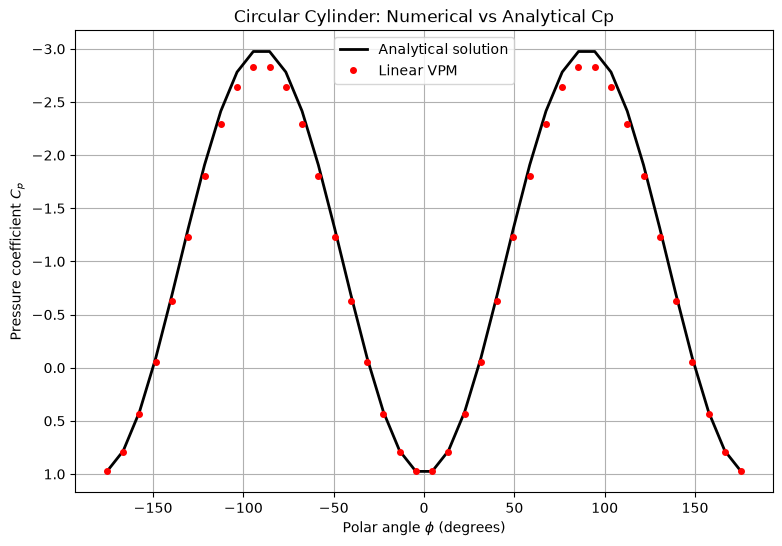
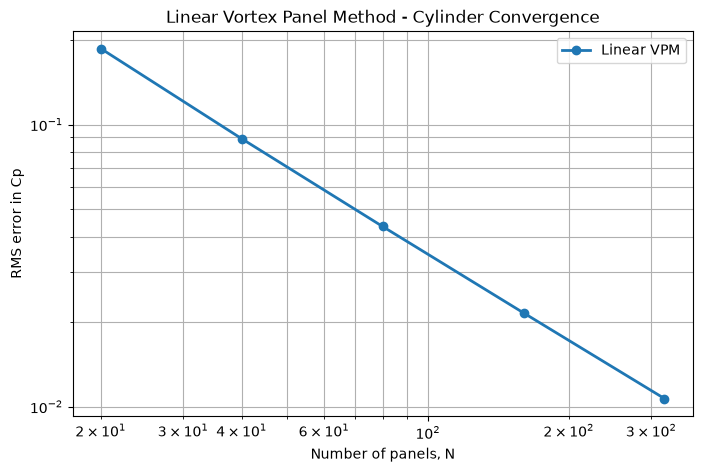

In [ ]:
# Saved figure output. The images are embedded in the notebook output.

**Figure discussion.** The left plot compares the computed and analytical cylinder pressure coefficients. The right plot shows the error reduction with panel refinement. The pressure distribution becomes progressively closer to the analytical curve as \(N\) increases. The convergence table above quantifies the same trend and confirms that the normal-flow residual remains near machine precision.

[Embedded side-by-side figures]
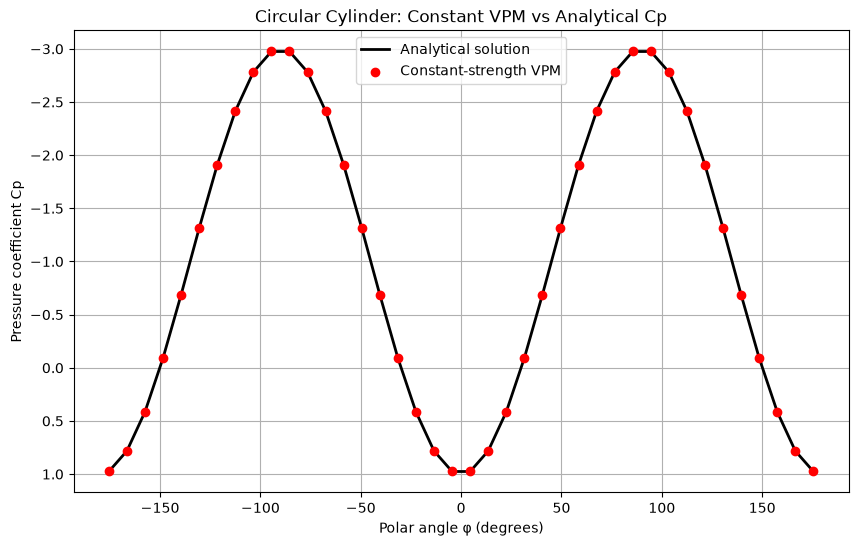

In [ ]:
# Saved figure output. The images are embedded in the notebook output.

**Figure discussion.** The constant-strength cylinder pressure curve lies essentially on the analytical result for the tested discretisation. The RMS errors in the table are around \(10^{-14}\)–\(10^{-13}\), which is close to double-precision numerical round-off. This is a successful verification for the cylinder case, but not proof of airfoil accuracy.

## 4. Airfoil verification and mesh convergence

Two airfoils are considered:

- **NACA 0012:** symmetric section, 12% thickness and zero camber.
- **NACA 4412:** cambered section, 4% maximum camber at 40% chord and 12% thickness.

The airfoil convergence study uses $V_\infty=1$ and $\alpha=4^\circ$

### 4.1 Linear-strength method: NACA 0012

| Panels | \(C_L\) | \(C_{D,p}\) | Normal RMS |
|---:|---:|---:|---:|
| 40 | 0.470687 | 0.010065 | $2.62\times10^{-16}$ |
| 80 | 0.476789 | 0.004672 | $4.72\times10^{-16}$ |
| 160 | 0.479749 | 0.002241 | $8.96\times10^{-16}$ |
| 320 | 0.481201 | 0.001097 | $1.97\times10^{-15}$ |
| 640 | 0.481919 | 0.000542 | $3.54\times10^{-15}$ |

**Results and discussion.** The lift coefficient increases toward a stable value as the panel count is increased. From 40 to 640 panels, $C_L$ changes from 0.470687 to 0.481919, with progressively smaller increments. This is evidence of mesh convergence for the linear-strength calculation. The pressure-drag coefficient decreases toward zero as the mesh is refined. This is consistent with the inviscid potential-flow model, which does not include viscous profile drag. The normal RMS residual remains close to machine precision.

### 4.2 Linear-strength method: NACA 4412

| Panels | \(C_L\) | \(C_{D,p}\) |
|---:|---:|---:|
| 40 | 0.503863 | 0.006429 |
| 80 | 0.511440 | 0.002948 |
| 160 | 0.514955 | 0.001407 |
| 320 | 0.516636 | 0.000688 |
| 640 | 0.517457 | 0.000340 |

**Results and discussion.** The NACA 4412 lift coefficient also increases smoothly with mesh refinement, approaching approximately 0.5175 at 640 panels. Unlike the symmetric NACA 0012 at zero incidence, the cambered NACA 4412 produces lift even at zero angle of attack. The pressure-drag coefficient decreases with refinement, as expected for an ideal inviscid calculation. The condition number increases with panel count, so finer meshes improve geometric resolution but make the linear system more sensitive numerically.

### 4.3 Constant-strength method: airfoil convergence

| Panels | NACA 0012 \(C_L\) | NACA 0012 \(C_{D,p}\) | NACA 4412 \(C_L\) | NACA 4412 \(C_{D,p}\) |
|---:|---:|---:|---:|---:|
| 40 | 0.502878 | -0.002789 | 0.995799 | -0.057052 |
| 80 | 0.542896 | -0.976455 | 0.951032 | -0.131680 |
| 160 | 0.726712 | -3.555818 | 0.991111 | -0.023424 |
| 320 | 0.964536 | -6.915022 | 0.924411 | -0.199488 |
| 640 | 1.282655 | -11.448805 | 0.846617 | -0.384925 |

**Results and discussion.** The constant-strength airfoil results do not show a stable convergence trend. For NACA 0012, the lift coefficient increases substantially with panel count, while the pressure-drag coefficient becomes increasingly negative. The NACA 4412 lift and pressure-drag values also vary non-monotonically. These results are not physically credible as converged airfoil force predictions. The method's successful cylinder verification does not guarantee reliable performance on airfoils; the present constant-strength airfoil implementation requires further numerical investigation before quantitative use.

[Embedded side-by-side figures]
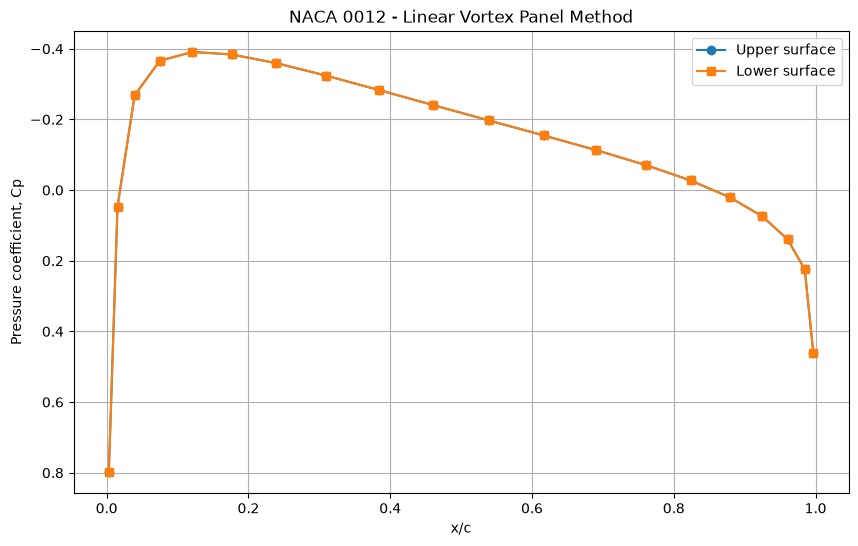
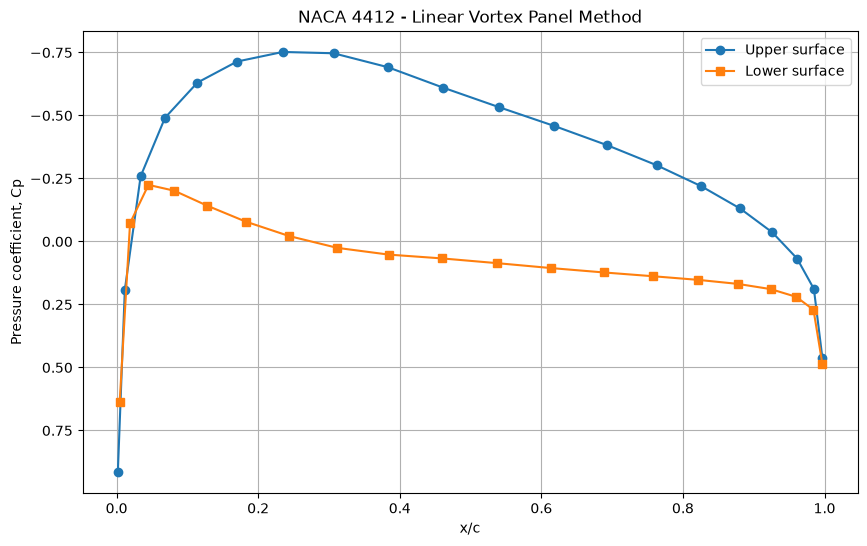

In [ ]:
# Saved figure output. The images are embedded in the notebook output.

**Figure discussion.** The plots show the pressure coefficient over the chord for the symmetric and cambered airfoils. For NACA 0012 at positive incidence, the upper-surface suction is stronger than the lower-surface suction over much of the chord, creating a positive pressure difference and positive lift. NACA 4412 has camber, which produces an asymmetric pressure distribution and positive lift even at zero incidence. The pressure coefficient follows $C_p=1-(V_t/V_\infty)^2$; regions of larger local speed correspond to lower pressure coefficient.

[Embedded side-by-side figures]
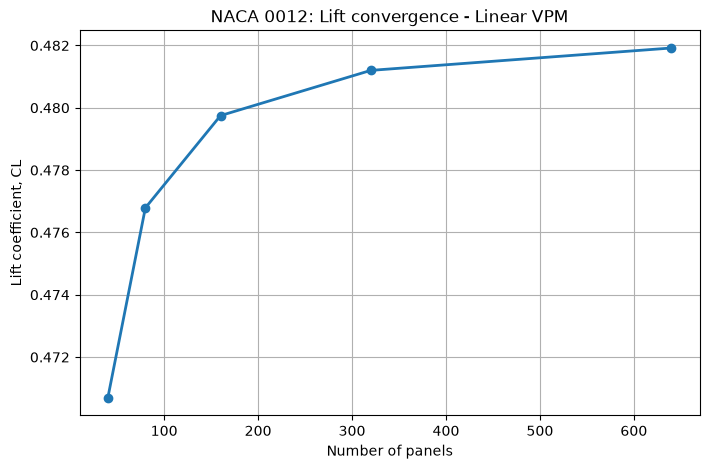
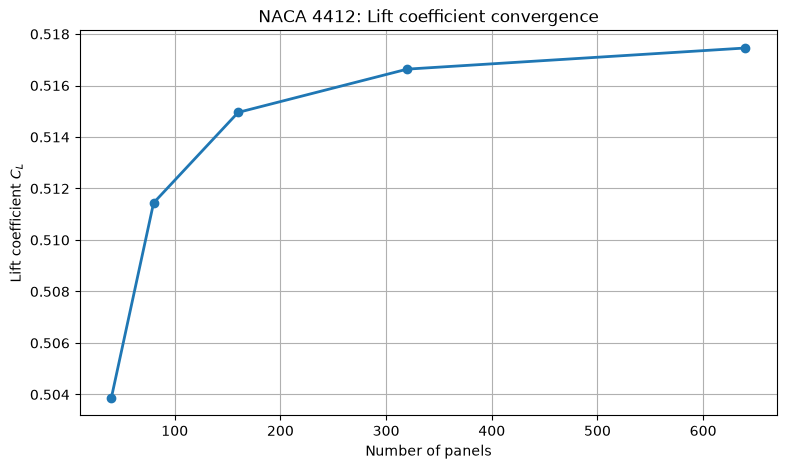

In [ ]:
# Saved figure output. The images are embedded in the notebook output.

**Figure discussion.** Both linear-strength lift curves approach a limiting value as the number of panels increases. The NACA 0012 sequence approaches $C_{L,BE} \approx 0.482$, while the NACA 4412 sequence approaches $C_{L,BE} \approx 0.517$. The smooth reduction in the change between successive meshes supports convergence of the lift prediction for these two cases.

In [2]:
# Saved figure output. The images are embedded in the notebook output.

**Figure discussion.** The pressure-drag coefficients decrease toward zero as the number of panels increases for both airfoils. This behaviour is consistent with ideal inviscid potential flow, in which viscous skin-friction drag and wake losses are absent. The calculated $C_{D,p}$ should therefore not be interpreted as the total drag of a real airfoil.

[Embedded side-by-side figures]
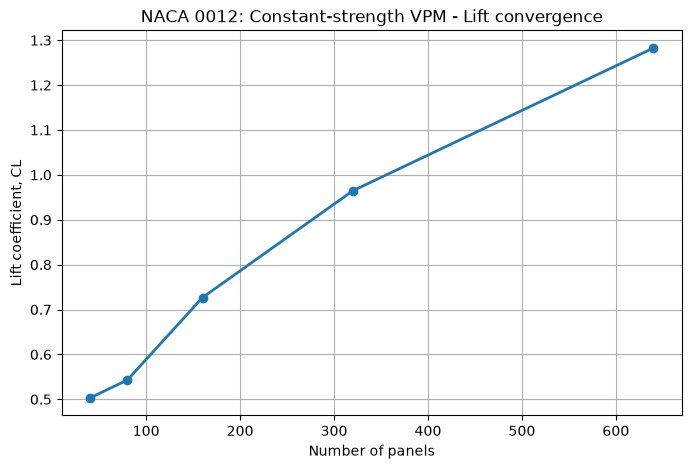
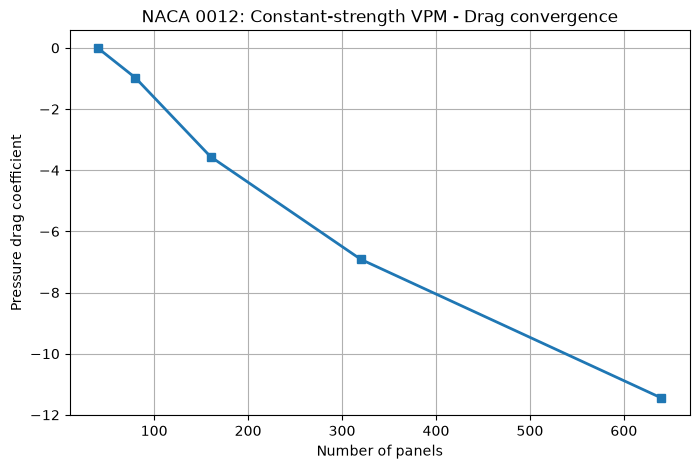

In [ ]:
# Saved figure output. The images are embedded in the notebook output.

**Figure discussion.** The NACA 0012 constant-strength lift and pressure-drag curves vary strongly with panel count. In particular, the pressure-drag coefficient becomes large and negative. These trends indicate that the present constant-strength airfoil predictions are not converged or physically reliable. Increasing the number of panels alone does not correct the underlying numerical issue.

[Embedded side-by-side figures]
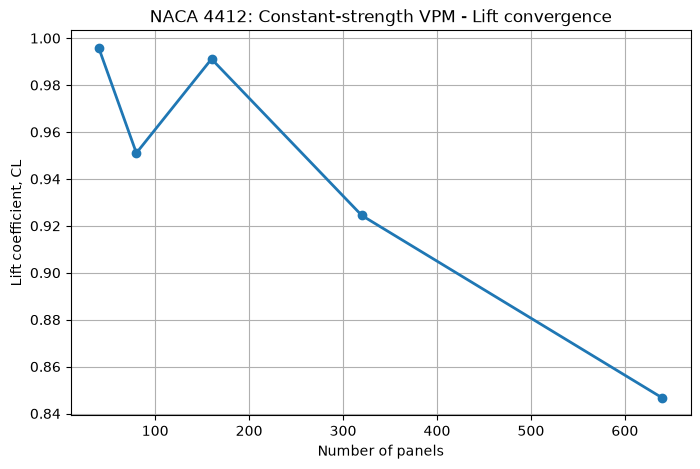
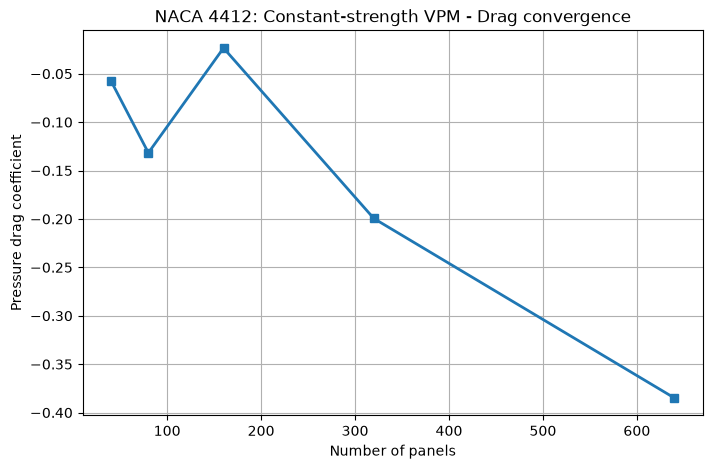

In [ ]:
# Saved figure output. The images are embedded in the notebook output.

**Figure discussion.** The NACA 4412 constant-strength results are also non-monotonic. The lift coefficient varies with panel count, and the pressure-drag coefficient is negative for all tabulated meshes. These outputs reinforce the need to treat the current constant-strength airfoil formulation as a diagnostic comparison rather than a validated predictive tool.

## 5. Effect of panel distribution

Uniform and cosine panel spacing were compared at 160 panels and $\alpha=4^\circ$. Uniform spacing distributes panels evenly along the chord. Cosine spacing clusters panels near the leading and trailing edges, where curvature and pressure gradients can be more demanding to resolve.

### 5.1 Linear-strength results

| Airfoil | Distribution | \(C_L\) | \(C_{D,p}\) |
|---|---|---:|---:|
| NACA 0012 | Uniform | 0.473563 | 0.010074 |
| NACA 0012 | Cosine | 0.479749 | 0.002241 |
| NACA 4412 | Uniform | 0.986752 | 0.009436 |
| NACA 4412 | Cosine | 0.993579 | 0.002243 |

**Results and discussion.** For NACA 0012, the lift predictions from the two distributions are relatively close, while the pressure-drag values differ. The NACA 4412 uniform-spacing lift in this comparison differs substantially from the corresponding panel-count convergence sequence, so the uniform/cosine comparison should be interpreted cautiously. Geometry generation and panel ordering must be consistent before a quantitative spacing conclusion is drawn.

### 5.2 Constant-strength results

| Airfoil | Distribution | \(C_L\) | \(C_{D,p}\) |
|---|---|---:|---:|
| NACA 0012 | Uniform | 2.963786 | 0.398649 |
| NACA 0012 | Cosine | 0.726712 | -3.555818 |
| NACA 4412 | Uniform | 2.077726 | 0.261105 |
| NACA 4412 | Cosine | 0.991111 | -0.023424 |

**Results and discussion.** The constant-strength predictions vary strongly with panel spacing and include nonphysical pressure-drag values. This is consistent with the poor constant-strength airfoil convergence already observed. Cosine spacing provides more resolution near the leading and trailing edges, but panel clustering alone cannot compensate for issues in the system formulation or post-processing.

In [1]:
# Saved figure output. The images are embedded in the notebook output.

**Figure discussion.** The geometry plots show the concentration of panels near the leading and trailing edges for cosine spacing, compared with the even spacing of the uniform distribution. Cosine spacing is generally useful for airfoils because it resolves regions of higher curvature and stronger pressure variation. However, the numerical comparison above shows that distribution effects must be evaluated together with mesh convergence and implementation consistency.

## 6. Prediction of airfoil characteristics and pressure distributions

### 6.1 Symmetric airfoil: NACA 0012

At zero angle of attack, the saved 40-panel linear-strength calculation gives $C_L\approx-8.6\times10^{-16}$, effectively zero. The upper/lower pressure-coefficient symmetry error is approximately $4.2\times10^{-15}$, and the maximum normal residual is approximately $6.7\times10^{-16}$. This is an important physical and numerical check: a symmetric airfoil at zero incidence should have no net lift in the ideal symmetric calculation.

At positive incidence $4^\circ$, the upper surface accelerates more strongly over much of the chord, producing lower pressure and positive lift. The 640-panel linear-strength result gives $C_L=0.481919$.

### 6.2 Cambered airfoil: NACA 4412

The NACA 4412 has positive camber and produces positive lift even at zero incidence. The saved 40-panel linear-strength result at zero incidence gives $C_L\approx0.503863$. At $4^\circ$, the 640-panel result approaches $C_L\approx0.517457$.

### 6.3 Pressure-coefficient interpretation

The upper-surface suction peak and the pressure difference between upper and lower surfaces contribute to lift. The pressure-force integration in this implementation does not include skin friction. Consequently, $C_{D,p}$ is a pressure-based inviscid force coefficient, not the total viscous profile drag of a real airfoil.

## 7. Effect of increasing airfoil thickness and model limitations

The thickness study uses symmetric NACA 00-series airfoils at $\alpha=4^\circ$, with the linear-strength method. A 40-panel coarse solution is compared with a 320-panel solution. The RMS difference between the coarse and fine $C_p$ distributions is used as a mesh-sensitivity measure.

### 7.1 Thickness-study results

| Thickness ratio | Airfoil | RMS coarse/fine \(C_p\) difference |
|---:|---|---:|
| 6% | NACA 0006 | 0.154753 |
| 12% | NACA 0012 | 0.117897 |
| 18% | NACA 0018 | 0.088661 |
| 24% | NACA 0024 | 0.076063 |

Additional fine-grid predictions:

| Thickness ratio | $C_L$ | $C_{D,p}$ | Maximum $|C_p|$ |
|---:|---:|---:|---:|
| 6% | 0.457874 | 0.002438 | 3.041072 |
| 12% | 0.479749 | 0.002241 | 1.481841 |
| 18% | 0.501788 | 0.002628 | 1.362380 |
| 24% | 0.524031 | 0.003169 | 1.499216 |

**Results and discussion.** The RMS coarse/fine $C_p$ difference decreases from 0.154753 at 6% thickness to 0.076063 at 24% thickness. Therefore, the present numerical data do **not** demonstrate the assignment's requested trend that predictive capability decreases as thickness increases. This RMS difference measures sensitivity to panel refinement; it is not an absolute error against experimental measurements or a validated higher-fidelity solution. It would be incorrect to claim that these values establish a loss of predictive capability with thickness.

### 7.2 Physical limitations of the panel method

The present method represents inviscid, incompressible, irrotational flow. It does not directly model:

- viscous boundary-layer growth and displacement effects;
- skin-friction drag and boundary-layer transition;
- flow separation, separated wakes, and stall;
- viscous pressure recovery;
- compressibility effects and shock waves.

For thicker or more highly loaded airfoils, real-flow viscous effects may become important. A potential-flow panel method cannot reproduce these phenomena directly. A convincing demonstration of decreasing predictive capability with thickness would require comparison against experimental measurements or a validated viscous CFD solution at matched Reynolds number and angle of attack.

[Embedded side-by-side figures]
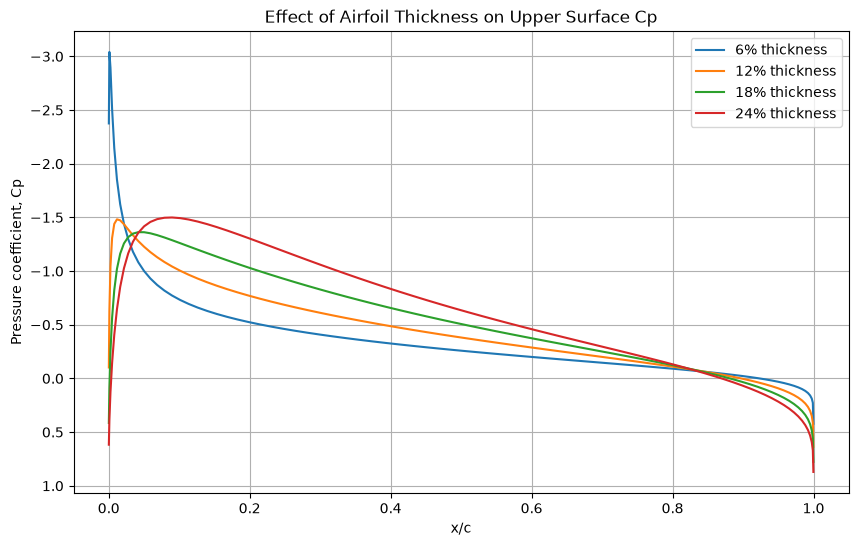
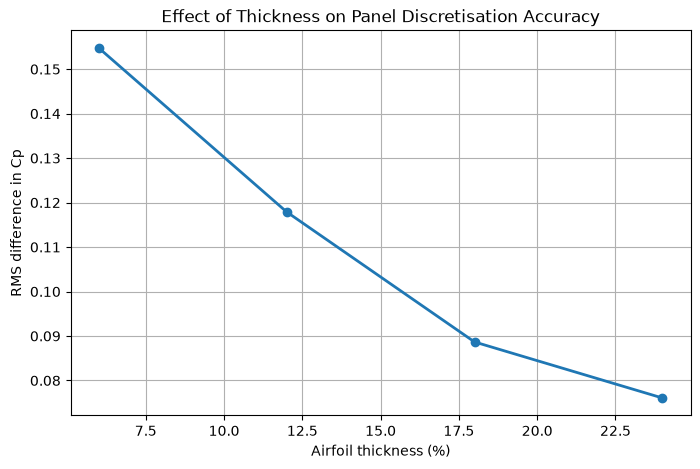

In [ ]:
# Saved figure output. The images are embedded in the notebook output.

**Figure discussion.** The left plot compares upper-surface $C_p$ distributions for the four thickness ratios. The right plot compares the coarse and fine panel solutions. The numerical RMS differences decrease with increasing thickness in this particular study. This must be reported as observed; it does not support the requested monotonic loss of predictive capability. A comparison with experimental or viscous CFD reference data would be needed to test that physical claim directly.

## 8. Overall conclusions

1. Constant-strength and linear-strength vortex panel algorithms were implemented. The required `vortex_panel_method_0()` and `vortex_panel_method_1()` wrappers accept arguments and return vortex strengths, tangential velocity, pressure coefficient, system matrices, and residual diagnostics.
2. The linear-strength cylinder solution converges toward the analytical cylinder pressure distribution as the panel count increases from 20 to 320.
3. The constant-strength cylinder calculation gives near-machine-precision agreement for the tested odd panel counts. This result is specific to the cylinder setup and does not establish airfoil accuracy.
4. The linear-strength method gives orderly lift convergence for NACA 0012 and NACA 4412. The current constant-strength airfoil results do not show reliable convergence.
5. Panel distribution affects predicted force coefficients. Cosine spacing clusters panels near the leading and trailing edges, but its benefit must be assessed together with consistent geometry generation and systematic refinement.
6. The symmetric NACA 0012 gives effectively zero lift at zero incidence, whereas the cambered NACA 4412 produces positive lift at zero incidence.
7. The thickness study shows a decreasing coarse/fine \(C_p\) difference with increasing thickness. It therefore does not establish the requested reduction in predictive capability.
8. The panel method is useful for idealised potential-flow pressure distributions, but cannot predict viscous drag, transition, separation, stall, or shock effects.

## 9. References and acknowledgement

### References

1. Anderson, J. D., *Fundamentals of Aerodynamics*, 6th ed., McGraw-Hill Education.
2. Katz, J. and Plotkin, A., *Low-Speed Aerodynamics*, 2nd ed., Cambridge University Press.
3. AE611 course material and assignment discussions on two-dimensional vortex panel methods.

### Acknowledgement of AI assistance

OpenAI ChatGPT was used as an AI-assisted learning and coding-support tool. Its assistance included explaining the physical basis of constant- and linear-strength vortex panel methods, discussing boundary conditions and the Kutta condition, helping organise selected Python routines and convergence studies, and supporting the interpretation and presentation of numerical results. The student is responsible for checking the implementation, executing the notebook, verifying the numerical results, and ensuring that the submitted work reflects their own understanding.

---

## Submission checklist

- [ ] Confirm student name and ID.
- [ ] Run the full implementation notebook separately if required for code verification.
- [ ] Open this report notebook and confirm that all paired figures display correctly.
- [ ] Confirm that tables and figures correspond to the final saved implementation outputs.
- [ ] Add any additional references or colleague discussions actually used.
- [ ] Submit the report notebook and implementation notebook according to the tutor's GitHub instructions.